# HAM10000 - Federated Client Partition

This notebook turns the frozen HAM10000 lesion-level split into a **federated** setting with 4 clients. It does **not** create a new train/val/test split.

**Inputs (read only):**

- `HAM10000_lesion_split_seed42_v2.csv`: frozen output of `01_ham10000_lesion_split.ipynb` (protocol v2)
- `HAM10000_metadata.csv`: original HAM10000 metadata; only the `dataset` column is used, to define clients

**Rules:**

1. Split first, clients second. Every image keeps the split of its lesion from the v2 manifest; the client is only the image's acquisition source (`dataset` column).
2. `dataset` and `dx_type` are never model inputs. `dataset` defines clients; `dx_type` is not exported.
3. Primary evaluation uses the **pooled** validation and test sets. Per-client results are secondary.

**What this notebook produces:** the FL partition manifest (`image_id, lesion_id, dx, split, client`), client-level tables and one figure for the proposal, all frozen with a fingerprint.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Inputs -------------------------------------------------------------
SPLIT_MANIFEST_PATH = Path(os.getenv(
    "HAM10000_SPLIT_MANIFEST_PATH",
    "../data-understanding/output-d.u/HAM10000_lesion_split_seed42_v2.csv",
))
METADATA_PATH = Path(os.getenv(
    "HAM10000_METADATA_PATH", "../dataset/HAM10000_metadata.csv",
))

# Fingerprint of the frozen v2 split (from 01_ham10000_lesion_split.ipynb).
SPLIT_MANIFEST_SHA256 = (
    "bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7"
)

# ---- Outputs ------------------------------------------------------------
OUTPUT_DIR = Path(os.getenv("HAM10000_FL_OUTPUT_DIR", "output-fl"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FL_MANIFEST_PATH = OUTPUT_DIR / "HAM10000_fl_partition_v1.csv"
CLIENT_SUMMARY_PATH = OUTPUT_DIR / "fl_client_summary_v1.csv"
CLIENT_CLASS_PATH = OUTPUT_DIR / "fl_client_class_counts_v1.csv"
CLIENT_SPLIT_CLASS_PATH = OUTPUT_DIR / "fl_client_split_class_counts_v1.csv"
CROSS_SOURCE_PATH = OUTPUT_DIR / "fl_cross_source_lesions_v1.csv"
CHECKS_PATH = OUTPUT_DIR / "fl_partition_checks_v1.json"
FIGURE_PATH = OUTPUT_DIR / "fl_client_class_distribution_v1.png"
LATEX_TABLE_PATH = OUTPUT_DIR / "fl_client_class_table_v1.tex"

# Fingerprint of the frozen FL partition produced by this notebook.
FROZEN_FL_MANIFEST_SHA256 = "0ab49e23b128c7d9f2d309bee762ade1d6ab69f04a31ca94096f29484c9a033d"

# ---- Constants ----------------------------------------------------------
SPLITS = ["train", "val", "test"]
CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]
# Client order: largest to smallest.
CLIENTS = ["vidir_molemax", "vidir_modern", "rosendahl", "vienna_dias"]

SPLIT_COLUMNS = ["image_id", "lesion_id", "dx", "split"]
FL_COLUMNS = ["image_id", "lesion_id", "dx", "split", "client"]


def fingerprint(frame: pd.DataFrame, columns: list) -> str:
    """OS-independent SHA-256: columns sorted by image_id, CSV, LF endings."""
    canonical = (
        frame[columns].sort_values("image_id")
        .to_csv(index=False, lineterminator="\n")
    )
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print(json.dumps(ENVIRONMENT, indent=2))

{
  "python": "3.14.3",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy": "2.4.3",
  "pandas": "2.3.3"
}


## 1. Load the frozen split and verify it

In [2]:
split_df = pd.read_csv(SPLIT_MANIFEST_PATH)
assert list(split_df.columns) == SPLIT_COLUMNS, split_df.columns.tolist()

split_sha = fingerprint(split_df, SPLIT_COLUMNS)
assert split_sha == SPLIT_MANIFEST_SHA256, (
    "The split manifest is not the frozen v2 manifest. "
    f"Got {split_sha}. Do not continue."
)
print(f"Split manifest verified: {SPLIT_MANIFEST_PATH}")
print(f"Rows: {len(split_df):,} | lesions: {split_df['lesion_id'].nunique():,}")

Split manifest verified: ..\data-understanding\output-d.u\HAM10000_lesion_split_seed42_v2.csv
Rows: 10,015 | lesions: 7,470


## 2. Attach the client (acquisition source) from the metadata

In [3]:
meta = pd.read_csv(METADATA_PATH)
assert {"image_id", "lesion_id", "dx", "dataset"} <= set(meta.columns), (
    "Metadata must contain the 'dataset' column (Harvard Dataverse HAM10000_metadata)."
)

fl = split_df.merge(
    meta[["image_id", "lesion_id", "dx", "dataset"]],
    on="image_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_meta"),
)

# Metadata and split manifest must agree on every row.
assert fl["dataset"].notna().all(), "Some images have no source in the metadata"
assert (fl["lesion_id"] == fl["lesion_id_meta"]).all()
assert (fl["dx"] == fl["dx_meta"]).all()

fl = fl.rename(columns={"dataset": "client"})[FL_COLUMNS]
assert set(fl["client"]) == set(CLIENTS), sorted(fl["client"].unique())
assert len(fl) == len(split_df)

display(fl.head())

,image_id,lesion_id,dx,split,client
0,ISIC_0024306,HAM_0000550,nv,test,vidir_molemax
1,ISIC_0024314,HAM_0002198,nv,test,vidir_modern
2,ISIC_0024320,HAM_0005039,nv,test,vidir_molemax
3,ISIC_0024321,HAM_0003511,nv,test,vidir_molemax
4,ISIC_0024326,HAM_0001812,nv,test,vidir_molemax


## 3. Client sizes and label skew

Each client is one acquisition source. The table shows how unevenly the 7 classes are spread across clients (non-IID label skew).

In [4]:
client_summary = (
    fl.groupby("client")
      .agg(images=("image_id", "size"), lesions=("lesion_id", "nunique"))
      .reindex(CLIENTS)
)
client_summary["image_share_pct"] = (100 * client_summary["images"] / len(fl)).round(1)

client_class = (
    pd.crosstab(fl["client"], fl["dx"])
      .reindex(index=CLIENTS, columns=CLASSES, fill_value=0)
)
client_class_pct = (100 * client_class.div(client_class.sum(axis=1), axis=0)).round(1)

# Share of each class held by each client (columns sum to 100%).
class_holder_pct = (100 * client_class / client_class.sum(axis=0)).round(1)

display(client_summary)
print("Images per client x class:")
display(client_class)
print("Class mix within each client (% of the client's images):")
display(client_class_pct)
print("Where each class lives (% of the class held by each client):")
display(class_holder_pct)

assert int(client_summary["images"].sum()) == len(fl)

,images,lesions,image_share_pct
client,,,
vidir_molemax,3954,3954,39.5
vidir_modern,3363,1695,33.6
rosendahl,2259,1552,22.6
vienna_dias,439,278,4.4


Images per client x class:


dx,nv,mel,bkl,bcc,akiec,vasc,df
client,,,,,,,
vidir_molemax,3720,24,124,2,0,54,30
vidir_modern,1832,680,475,211,32,82,51
rosendahl,803,342,490,296,295,3,30
vienna_dias,350,67,10,5,0,3,4


Class mix within each client (% of the client's images):


dx,nv,mel,bkl,bcc,akiec,vasc,df
client,,,,,,,
vidir_molemax,94.1,0.6,3.1,0.1,0.0,1.4,0.8
vidir_modern,54.5,20.2,14.1,6.3,1.0,2.4,1.5
rosendahl,35.5,15.1,21.7,13.1,13.1,0.1,1.3
vienna_dias,79.7,15.3,2.3,1.1,0.0,0.7,0.9


Where each class lives (% of the class held by each client):


dx,nv,mel,bkl,bcc,akiec,vasc,df
client,,,,,,,
vidir_molemax,55.5,2.2,11.3,0.4,0.0,38.0,26.1
vidir_modern,27.3,61.1,43.2,41.1,9.8,57.7,44.3
rosendahl,12.0,30.7,44.6,57.6,90.2,2.1,26.1
vienna_dias,5.2,6.0,0.9,1.0,0.0,2.1,3.5


## 4. Lesions that appear in more than one client

Some lesions were imaged by two acquisition systems. Because the split was made per lesion **before** assigning clients, such a lesion is always in a single split, even if its images sit in two clients.

In [5]:
lesion_sources = fl.groupby("lesion_id").agg(
    n_clients=("client", "nunique"),
    n_splits=("split", "nunique"),
    n_images=("image_id", "size"),
    dx=("dx", "first"),
    split=("split", "first"),
)
cross_source = lesion_sources[lesion_sources["n_clients"] > 1].copy()
cross_source["clients"] = (
    fl[fl["lesion_id"].isin(cross_source.index)]
      .groupby("lesion_id")["client"]
      .apply(lambda s: " + ".join(sorted(s.unique())))
)

print(f"Lesions in >1 client: {len(cross_source)} "
      f"({int(cross_source['n_images'].sum())} images)")
display(cross_source.reset_index())

# Leakage guard: every lesion, including cross-source ones, has exactly one split.
assert (lesion_sources["n_splits"] == 1).all()

Lesions in >1 client: 9 (26 images)


,lesion_id,n_clients,n_splits,n_images,dx,split,clients
0,HAM_0000492,2,1,3,mel,val,vidir_modern + vidir_molemax
1,HAM_0000871,2,1,3,mel,train,vidir_modern + vidir_molemax
2,HAM_0001726,2,1,3,mel,test,vidir_modern + vidir_molemax
3,HAM_0002534,2,1,3,mel,val,vidir_modern + vidir_molemax
4,HAM_0003194,2,1,2,mel,val,vidir_modern + vidir_molemax
5,HAM_0003558,2,1,3,mel,train,vidir_modern + vidir_molemax
6,HAM_0004979,2,1,3,mel,train,vidir_modern + vidir_molemax
7,HAM_0005481,2,1,3,mel,train,vidir_modern + vidir_molemax
8,HAM_0006453,2,1,3,mel,test,vidir_modern + vidir_molemax


## 5. Client x split x class

This is the table the FL experiments depend on. Cells with zero training images mean that a client **never sees** that class during local training.

In [6]:
client_split_class = (
    fl.groupby(["client", "split", "dx"]).size()
      .unstack("dx", fill_value=0)
      .reindex(columns=CLASSES, fill_value=0)
      .reindex(pd.MultiIndex.from_product([CLIENTS, SPLITS], names=["client", "split"]),
               fill_value=0)
)
client_split_class["total"] = client_split_class.sum(axis=1)
display(client_split_class)

# Split proportions inside each client (should stay close to 70/15/15).
split_within_client = (
    100 * pd.crosstab(fl["client"], fl["split"], normalize="index")
).reindex(index=CLIENTS, columns=SPLITS).round(1)
print("Split proportions inside each client (%):")
display(split_within_client)

# Classes a client never trains on.
train_counts = client_split_class.xs("train", level="split")[CLASSES]
missing_in_train = {
    c: [k for k in CLASSES if train_counts.loc[c, k] == 0] for c in CLIENTS
}
print("Classes with 0 training images per client:", missing_in_train)

dx                     nv  mel  bkl  bcc  akiec  vasc  df  total
client        split                                             
vidir_molemax train  2602   13   82    0      0    38  27   2762
              val     555    4   23    0      0    10   0    592
              test    563    7   19    2      0     6   3    600
vidir_modern  train  1308  449  340  151     24    57  27   2356
              val     259  121   63   27      7    12  12    501
              test    265  110   72   33      1    13  12    506
rosendahl     train   537  250  343  208    198     2  15   1553
              val     148   47   72   53     46     0  10    376
              test    118   45   75   35     51     1   5    330
vienna_dias   train   236   61    7    2      0     2   2    310
              val      56    1    2    2      0     0   2     63
              test     58    5    1    1      0     1   0     66

Split proportions inside each client (%):


split,train,val,test
client,,,
vidir_molemax,69.9,15.0,15.2
vidir_modern,70.1,14.9,15.0
rosendahl,68.7,16.6,14.6
vienna_dias,70.6,14.4,15.0


Classes with 0 training images per client: {'vidir_molemax': ['bcc', 'akiec'], 'vidir_modern': [], 'rosendahl': [], 'vienna_dias': ['akiec']}


## 6. Evaluation design check

Per-client validation and test sets are too small for some classes, so model selection and the primary metrics use the **pooled** sets. In real FL a server would not hold a validation set; this is a simulation assumption and must be listed under Threats to Validity.

In [7]:
MIN_IMAGES_FOR_PER_CLASS_METRIC = 10

per_client_eval = client_split_class.loc[(slice(None), ["val", "test"]), CLASSES]
per_client_long = per_client_eval.stack().rename("images").reset_index()
sparse_cells = per_client_long[
    per_client_long["images"] < MIN_IMAGES_FOR_PER_CLASS_METRIC
].reset_index(drop=True)
print(f"Per-client val/test cells with < {MIN_IMAGES_FOR_PER_CLASS_METRIC} images: "
      f"{len(sparse_cells)} of {per_client_eval.size}")
display(sparse_cells)

pooled = fl[fl["split"].isin(["val", "test"])].groupby(["split", "dx"]).size().unstack()
pooled = pooled.reindex(index=["val", "test"], columns=CLASSES)
print("Pooled evaluation sets:")
display(pooled)

# Every class must be present in the pooled val and test sets.
assert (pooled > 0).all().all()

Per-client val/test cells with < 10 images: 26 of 56


,client,split,dx,images
0,vidir_molemax,val,mel,4
1,vidir_molemax,val,bcc,0
2,vidir_molemax,val,akiec,0
3,vidir_molemax,val,df,0
4,vidir_modern,val,akiec,7
5,rosendahl,val,vasc,0
6,vienna_dias,val,mel,1
7,vienna_dias,val,bkl,2
8,vienna_dias,val,bcc,2
9,vienna_dias,val,akiec,0


Pooled evaluation sets:


dx,nv,mel,bkl,bcc,akiec,vasc,df
split,,,,,,,
val,1018,173,160,82,53,22,24
test,1004,167,167,71,52,21,20


## 7. Figure for the proposal

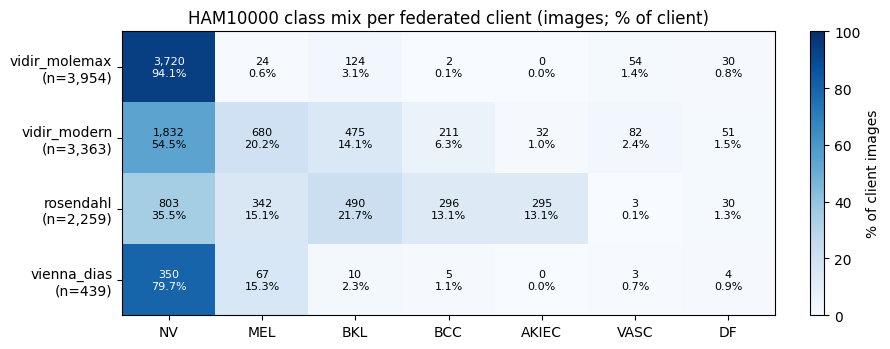

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(client_class_pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(CLASSES)), [c.upper() for c in CLASSES])
ax.set_yticks(
    range(len(CLIENTS)),
    [f"{c}\n(n={client_summary.loc[c, 'images']:,})" for c in CLIENTS],
)
for i, client in enumerate(CLIENTS):
    for j, cls in enumerate(CLASSES):
        pct = client_class_pct.loc[client, cls]
        count = client_class.loc[client, cls]
        ax.text(j, i, f"{count:,}\n{pct:.1f}%", ha="center", va="center",
                fontsize=8, color="white" if pct > 55 else "black")

ax.set_title("HAM10000 class mix per federated client (images; % of client)")
fig.colorbar(im, ax=ax, label="% of client images", fraction=0.025)
plt.tight_layout()
plt.savefig(FIGURE_PATH, dpi=300)
plt.show()

## 8. Save and freeze the FL partition

In [9]:
fl_to_save = fl[FL_COLUMNS].sort_values(["client", "split", "image_id"])
fl_sha = fingerprint(fl_to_save, FL_COLUMNS)
print(f"FL partition SHA-256: {fl_sha}")

if FROZEN_FL_MANIFEST_SHA256 != "PENDING" and fl_sha != FROZEN_FL_MANIFEST_SHA256:
    raise RuntimeError(
        "The FL partition differs from the frozen version. Check the inputs; "
        "do not overwrite the saved partition."
    )

if FL_MANIFEST_PATH.exists():
    saved_sha = fingerprint(pd.read_csv(FL_MANIFEST_PATH), FL_COLUMNS)
    assert saved_sha == fl_sha, (
        f"Saved FL partition at {FL_MANIFEST_PATH} does not match (SHA-256 {saved_sha})."
    )
    print("Saved FL partition matches; not rewritten.")
else:
    fl_to_save.to_csv(FL_MANIFEST_PATH, index=False, lineterminator="\n")
    print(f"FL partition written: {FL_MANIFEST_PATH}")

client_summary.reset_index().to_csv(CLIENT_SUMMARY_PATH, index=False, lineterminator="\n")
client_class.reset_index().to_csv(CLIENT_CLASS_PATH, index=False, lineterminator="\n")
client_split_class.reset_index().to_csv(CLIENT_SPLIT_CLASS_PATH, index=False, lineterminator="\n")
cross_source.reset_index().to_csv(CROSS_SOURCE_PATH, index=False, lineterminator="\n")

checks = {
    "partition_version": "v1",
    "split_protocol": "v2 (frozen lesion split, seed 42)",
    "split_manifest_sha256": SPLIT_MANIFEST_SHA256,
    "client_definition": "HAM10000 metadata column 'dataset' (acquisition source)",
    "clients": {c: {"images": int(client_summary.loc[c, "images"]),
                    "lesions": int(client_summary.loc[c, "lesions"])} for c in CLIENTS},
    "client_class_counts": {c: {k: int(client_class.loc[c, k]) for k in CLASSES} for c in CLIENTS},
    "classes_missing_in_client_train": missing_in_train,
    "cross_source_lesions": {
        "lesions": int(len(cross_source)),
        "images": int(cross_source["n_images"].sum()),
        "all_in_single_split": bool((lesion_sources["n_splits"] == 1).all()),
    },
    "primary_evaluation": "pooled val/test across clients",
    "excluded_from_model_inputs": ["dataset", "dx_type"],
    "fl_manifest_sha256": fl_sha,
    "fl_manifest_sha256_definition": (
        "SHA-256 of [image_id, lesion_id, dx, split, client] sorted by image_id, "
        "CSV without index, LF line endings"
    ),
    "environment": ENVIRONMENT,
}
_ = CHECKS_PATH.write_text(json.dumps(checks, indent=2), encoding="utf-8")

FL partition SHA-256: 0ab49e23b128c7d9f2d309bee762ade1d6ab69f04a31ca94096f29484c9a033d
FL partition written: output-fl\HAM10000_fl_partition_v1.csv


### LaTeX table for the IEEE proposal

Writes the client x class table as a plain `tabular` that compiles with the IEEEtran template (no extra packages).

In [10]:
header = "Client & Images & " + " & ".join(c.upper() for c in CLASSES) + " \\\\"
rows = []
for c in CLIENTS:
    counts = " & ".join(f"{int(client_class.loc[c, k]):,}" for k in CLASSES)
    name = c.replace("_", "\\_")
    rows.append(f"{name} & {int(client_summary.loc[c, 'images']):,} & {counts} \\\\")

latex = "\n".join([
    "\\begin{table}[t]",
    "\\caption{Class distribution of the four HAM10000 acquisition sources used as federated clients}",
    "\\label{tab:fl_clients}",
    "\\centering",
    "\\footnotesize",
    "\\setlength{\\tabcolsep}{3pt}",
    "\\begin{tabular}{lrrrrrrrr}",
    "\\hline",
    header,
    "\\hline",
    *rows,
    "\\hline",
    "\\end{tabular}",
    "\\end{table}",
])
_ = LATEX_TABLE_PATH.write_text(latex + "\n", encoding="utf-8")
print(latex)

for p in [FL_MANIFEST_PATH, CLIENT_SUMMARY_PATH, CLIENT_CLASS_PATH, CLIENT_SPLIT_CLASS_PATH,
          CROSS_SOURCE_PATH, CHECKS_PATH, FIGURE_PATH, LATEX_TABLE_PATH]:
    print(f"Saved: {p.resolve()}")

\begin{table}[t]
\caption{Class distribution of the four HAM10000 acquisition sources used as federated clients}
\label{tab:fl_clients}
\centering
\footnotesize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{lrrrrrrrr}
\hline
Client & Images & NV & MEL & BKL & BCC & AKIEC & VASC & DF \\
\hline
vidir\_molemax & 3,954 & 3,720 & 24 & 124 & 2 & 0 & 54 & 30 \\
vidir\_modern & 3,363 & 1,832 & 680 & 475 & 211 & 32 & 82 & 51 \\
rosendahl & 2,259 & 803 & 342 & 490 & 296 & 295 & 3 & 30 \\
vienna\_dias & 439 & 350 & 67 & 10 & 5 & 0 & 3 & 4 \\
\hline
\end{tabular}
\end{table}
Saved: D:\AI\Kì 5\DPL302m\Federated-Learning-for-Skin-Lesion-Classification\federated-learning\output-fl\HAM10000_fl_partition_v1.csv
Saved: D:\AI\Kì 5\DPL302m\Federated-Learning-for-Skin-Lesion-Classification\federated-learning\output-fl\fl_client_summary_v1.csv
Saved: D:\AI\Kì 5\DPL302m\Federated-Learning-for-Skin-Lesion-Classification\federated-learning\output-fl\fl_client_class_counts_v1.csv
Saved: D:\AI\Kì 5\DPL302m\Federat

## 9. Takeaway

- 4 clients = 4 HAM10000 acquisition sources; the split is inherited unchanged from protocol v2.
- Label skew is strong (see Section 3); some clients never train on some classes (Section 5).
- Lesions imaged by two sources stay in one split, so FL clients cannot leak lesions across train/val/test.
- Primary metrics use pooled val/test; per-client metrics are secondary.
- All FL training code loads `HAM10000_fl_partition_v1.csv` and checks its fingerprint.